## Random Forest —  (saliency maps) 

### 1. Imports & configuration

In [1]:
import os, json, pickle, joblib, gc, time
import numpy as np
import pandas as pd
from itertools import combinations
from collections import Counter
from concurrent.futures import ProcessPoolExecutor, wait, FIRST_COMPLETED, as_completed
from PIL import Image

from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score, recall_score, f1_score, accuracy_score,
    roc_auc_score, confusion_matrix
)
from scipy.stats import skew, kurtosis

import matplotlib.pyplot as plt
import seaborn as sns

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(it, **kwargs):
        return it

import warnings
warnings.filterwarnings("ignore")


In [ ]:
CKPT_DIR = '/kaggle/working' if os.path.isdir('/kaggle/working') else '.'

RFE_CKPT  = os.path.join(CKPT_DIR, 'ckpt_rfe_selection.pkl')
SEED    = 42
N_FOLDS = 5
import random
random.seed(SEED)
np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

print(f"CKPT_DIR = {CKPT_DIR} | SEED = {SEED} | N_FOLDS = {N_FOLDS}")

CKPT_DIR = /kaggle/working | SEED = 42 | N_FOLDS = 5


### 2.Dataset DREAM

In [3]:
KAGGLE_INPUT = '/kaggle/input'

def find_dream_root(base):
    for root, dirs, files in os.walk(base):
        json_subdirs = [
            d for d in dirs
            if any(f.endswith('.json')
                   for f in os.listdir(os.path.join(root, d))
                   if os.path.isfile(os.path.join(root, d, f)))
        ]
        if json_subdirs:
            return root
    return None

if os.path.isdir(KAGGLE_INPUT):
    print("Environment detected : Kaggle")
    dream_root = find_dream_root(KAGGLE_INPUT)
    if dream_root is None:
        raise RuntimeError(
            "DREAM dataset not found in /kaggle/input/\n"
            "Verifie que le dataset est bien ajoute au notebook via 'Add Data'."
        )
    extract_path = dream_root
    print(f"Dataset DREAM trouve dans : {extract_path}")
else:
    print("Environment detected : Colab / local")
    from google.colab import drive
    drive.mount('/content/drive')
    dream_path   = '/content/drive/MyDrive/Master_TSA/Datasets/Dream dataset/snd1156-1-1.zip'
    extract_path = '/content/DREAM'
    os.makedirs(extract_path, exist_ok=True)
    import zipfile
    with zipfile.ZipFile(dream_path, 'r') as z:
        z.extractall(extract_path)
    print("Complete extraction in :", extract_path)


Environment detected : Kaggle
Dataset DREAM trouve dans : /kaggle/input/datasets/rimbenjaballah26/dream-dataset


In [4]:
def safe_first(obj):
    if isinstance(obj, list):
        return obj[0] if obj else {}
    return obj if obj is not None else {}

def assign_label(module, comm, inter):
    try:
        module = int(module)
    except (TypeError, ValueError):
        module = 1
    total = (comm or 0) + (inter or 0)
    cutoffs = {1: (7, 12), 2: (8, 12), 3: (7, 10)}
    asd_cut, aut_cut = cutoffs.get(module, (7, 12))
    if total >= aut_cut:
        return 'Autistic Disorder'
    elif total >= asd_cut:
        return 'ASD (AS, PDD)'
    return None

def to_float_array(lst):
    if not lst:
        return np.empty(0, dtype=float)
    return pd.to_numeric(pd.Series(lst), errors='coerce').to_numpy(dtype=float)

def build_xyz_array(d, keys):
    cols = [to_float_array(d.get(k, [])) for k in keys]
    n = max((len(c) for c in cols), default=0)
    if n == 0:
        return None
    out = np.full((n, len(keys)), np.nan)
    for i, c in enumerate(cols):
        out[:len(c), i] = c
    return out

all_json_files = []
for user_dir in sorted(os.listdir(extract_path)):
    user_path = os.path.join(extract_path, user_dir)
    if not os.path.isdir(user_path):
        continue
    for fname in sorted(os.listdir(user_path)):
        if fname.endswith(".json"):
            all_json_files.append(os.path.join(user_path, fname))

print(f"Fichiers JSON detectes : {len(all_json_files)}")


Fichiers JSON detectes : 3121


### 3. Split train/test 


In [ ]:
if os.path.exists(RFE_CKPT):
    print(f"Checkpoint trouve : {RFE_CKPT} -> chargement (pas de recalcul).")
    with open(RFE_CKPT, 'rb') as f:
        _ck = pickle.load(f)
    le               = _ck['le']
    train_pids       = _ck['train_pids']
    test_pids_unique = _ck['test_pids_unique']

else:
    print("Aucun checkpoint RFE trouve -> lancement de la Partie A (extraction + split + RFE).")
    print("Cette etape peut prendre du temps la premiere fois (elle lit tous les JSON).")

    #Constantes d'extraction 
    SEGMENT_SIZE = 25
    JOINTS = ['Head', 'ShoulderCenter', 'ShoulderLeft', 'ShoulderRight',
              'ElbowLeft', 'ElbowRight', 'WristLeft', 'WristRight',
              'HandLeft', 'HandRight']
    JOINT_MAP_RAW = {
        'head':           'Head',
        'sholder_center': 'ShoulderCenter',
        'sholder_left':   'ShoulderLeft',
        'sholder_right':  'ShoulderRight',
        'elbow_left':     'ElbowLeft',
        'elbow_right':    'ElbowRight',
        'wrist_left':     'WristLeft',
        'wrist_right':    'WristRight',
        'hand_left':      'HandLeft',
        'hand_right':     'HandRight',
    }
    ANGLE_TRIPLETS = [
        ('Head',          'ShoulderCenter', 'ShoulderLeft'),
        ('Head',          'ShoulderCenter', 'ShoulderRight'),
        ('ShoulderLeft',  'ShoulderCenter', 'ShoulderRight'),
        ('ShoulderCenter','ShoulderLeft',   'ElbowLeft'),
        ('ShoulderCenter','ShoulderRight',  'ElbowRight'),
        ('ShoulderLeft',  'ElbowLeft',      'WristLeft'),
        ('ShoulderRight', 'ElbowRight',     'WristRight'),
        ('ElbowLeft',     'WristLeft',      'HandLeft'),
        ('ElbowRight',    'WristRight',     'HandRight'),
    ]

    N_WORKERS = max(1, min((os.cpu_count() or 2) - 1, 8))
    MAX_IN_FLIGHT = N_WORKERS * 4
    CHECKPOINT_EVERY = 200
    CHECKPOINT_SECONDS = 180
    CHECKPOINT_PKL = os.path.join(CKPT_DIR, 'feat_checkpoint.pkl')

    def euclidean_dist(A, B):
        return float(np.sqrt(np.sum((A - B) ** 2)))

    def angle_between(P1, P2, P3):
        v1 = P1 - P2; v2 = P3 - P2
        cos_a = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2) + 1e-9)
        return float(np.degrees(np.arccos(np.clip(cos_a, -1, 1))))

    def extract_features_arrays(seg_arrays, gaze_arrays, normative):
        feats = {}
        means = {j: seg_arrays[j].mean(axis=0) for j in JOINTS}
        for jA, jB in combinations(JOINTS, 2):
            feats[f'{jA}_{jB}_dist'] = euclidean_dist(means[jA], means[jB])
        for P1n, P2n, P3n in ANGLE_TRIPLETS:
            feats[f'{P1n}_{P2n}_{P3n}_angle'] = angle_between(means[P1n], means[P2n], means[P3n])
        vectors = {}
        for name in ['head', 'eye']:
            G_arr = gaze_arrays.get(name)
            if G_arr is not None and G_arr.shape[0] > 0:
                G = G_arr.mean(axis=0)
                mag = np.linalg.norm(G) + 1e-9
                feats[f'{name}_alpha'] = float(np.degrees(np.arccos(np.clip(G[0]/mag, -1, 1))))
                feats[f'{name}_beta']  = float(np.degrees(np.arccos(np.clip(G[1]/mag, -1, 1))))
                feats[f'{name}_gamma'] = float(np.degrees(np.arccos(np.clip(G[2]/mag, -1, 1))))
                vectors[name] = G
            else:
                feats[f'{name}_alpha'] = feats[f'{name}_beta'] = feats[f'{name}_gamma'] = np.nan
        if 'head' in vectors and 'eye' in vectors:
            H, E = vectors['head'], vectors['eye']
            H_mag = np.linalg.norm(H) + 1e-9
            E_mag = np.linalg.norm(E) + 1e-9
            cos_t = np.dot(E, H) / (E_mag * H_mag)
            theta = np.arccos(np.clip(cos_t, -1, 1))
            feats['gaze_angle_EH'] = float(np.degrees(theta))
            feats['gaze_zone_phi'] = float(np.degrees(np.arctan2(H_mag*np.sin(theta), E_mag+H_mag*np.cos(theta))))
        else:
            feats['gaze_angle_EH'] = feats['gaze_zone_phi'] = np.nan
        for j in JOINTS:
            for ax_i, ax in enumerate(['x','y','z']):
                col = f'skeleton_{j.lower()}_{ax}'
                feats[f'{col}_std'] = float(seg_arrays[j][:, ax_i].std())
        for name in ['head', 'eye']:
            G_arr = gaze_arrays.get(name)
            for ax_i, ax in enumerate(['rx','ry','rz']):
                col = f'{name}_gaze_{ax}'
                feats[f'{col}_std'] = float(G_arr[:, ax_i].std()) if G_arr is not None else np.nan
        feats.update(normative)
        return feats

    def process_json_file(fpath):
        with open(fpath) as f:
            data = json.load(f)
        p         = safe_first(data.get('participant', {}))
        ados      = data.get('ados', {})
        ados_data = ados.get('preTest', {}) if isinstance(ados, dict) else {}
        t         = data.get('task', {}) if isinstance(data.get('task'), dict) else {}
        comm   = ados_data.get('communication')
        inter  = ados_data.get('interaction')
        module = ados_data.get('module')
        label  = assign_label(module, comm, inter)
        if label is None:
            return []
        pid        = p.get('id', p.get('child_id'))
        age_months = p.get('ageInMonths', p.get('age_months'))
        gender_raw = str(p.get('gender', 'unknown'))
        cond_raw   = data.get('condition', p.get('condition', 'SHT'))
        difficulty_raw = t.get('difficultyLevel', t.get('task_ability', 0))
        ability_raw= str(t.get('ability', t.get('task_ability', 'unknown')))
        ados_score = (comm or 0) + (inter or 0)
        skel = data.get('skeleton', {})
        hg   = data.get('head_gaze', {})
        eg   = data.get('eye_gaze',  {})
        joint_series = {}
        for raw_key, canon in JOINT_MAP_RAW.items():
            joint = skel.get(raw_key, {})
            joint_series[canon] = build_xyz_array(joint, ('x', 'y', 'z')) if isinstance(joint, dict) else None
        gaze_series = {
            'head': build_xyz_array(hg, ('rx', 'ry', 'rz')),
            'eye':  build_xyz_array(eg, ('rx', 'ry', 'rz')),
        }
        lengths = [a.shape[0] for a in joint_series.values() if a is not None]
        lengths += [a.shape[0] for a in gaze_series.values() if a is not None]
        if not lengths:
            return []
        n_frames = max(lengths)
        n_segs = n_frames // SEGMENT_SIZE
        if n_segs == 0:
            return []
        feats_list = []
        for i in range(n_segs):
            s, e = i * SEGMENT_SIZE, (i + 1) * SEGMENT_SIZE
            seg_arrays = {}
            for j in JOINTS:
                arr = joint_series[j]
                if arr is not None and s < arr.shape[0]:
                    seg_arrays[j] = arr[s:min(e, arr.shape[0])]
                    if len(seg_arrays[j]) < SEGMENT_SIZE:
                        pad = np.full((SEGMENT_SIZE - len(seg_arrays[j]), 3), np.nan)
                        seg_arrays[j] = np.vstack([seg_arrays[j], pad])
                else:
                    seg_arrays[j] = np.full((SEGMENT_SIZE, 3), np.nan)
            seg_gaze = {}
            for name, arr in gaze_series.items():
                if arr is not None and s < arr.shape[0]:
                    sliced = arr[s:min(e, arr.shape[0])]
                    if len(sliced) < SEGMENT_SIZE:
                        pad = np.full((SEGMENT_SIZE - len(sliced), 3), np.nan)
                        sliced = np.vstack([sliced, pad])
                    seg_gaze[name] = sliced
                else:
                    seg_gaze[name] = None
            normative = {
                'participant_ageInMonths': age_months,
                'age_group':    0,
                'gender':       gender_raw,
                'task_ability': ability_raw,
                'task_difficulty': difficulty_raw,
            }
            feats = extract_features_arrays(seg_arrays, seg_gaze, normative)
            feats['participant_id'] = pid
            feats['label']          = label
            feats['ados_score']     = ados_score
            feats['age_months']     = age_months
            feats['condition']      = cond_raw
            feats_list.append(feats)
        return feats_list

    processed_set = set()
    all_feats = []
    if os.path.exists(CHECKPOINT_PKL):
        with open(CHECKPOINT_PKL, 'rb') as f:
            ck = pickle.load(f)
        processed_set = ck.get('processed', set())
        all_feats     = ck.get('feats', [])
        print(f"Checkpoint extraction trouve -> {len(processed_set)} fichiers deja traites.")

    remaining_files = [f for f in all_json_files if f not in processed_set]
    print(f"Fichiers restants a traiter : {len(remaining_files)}")

    def save_checkpoint():
        with open(CHECKPOINT_PKL, 'wb') as f:
            pickle.dump({'feats': all_feats, 'processed': processed_set}, f)

    n_done = len(processed_set)
    t0 = time.time()

    if remaining_files:
        file_iter = iter(remaining_files)
        last_ckpt_time = time.time()
        with ProcessPoolExecutor(max_workers=N_WORKERS) as ex:
            futures = {}
            for _ in range(min(MAX_IN_FLIGHT, len(remaining_files))):
                fp = next(file_iter)
                futures[ex.submit(process_json_file, fp)] = fp
            pbar = tqdm(total=len(remaining_files), desc="Extraction features")
            while futures:
                done, _ = wait(futures, return_when=FIRST_COMPLETED)
                for fut in done:
                    fp = futures.pop(fut)
                    try:
                        feats = fut.result()
                        all_feats.extend(feats)
                    except Exception as e:
                        pass
                    processed_set.add(fp)
                    n_done += 1
                    pbar.update(1)
                    try:
                        nf = next(file_iter)
                        futures[ex.submit(process_json_file, nf)] = nf
                    except StopIteration:
                        pass
                    now = time.time()
                    if n_done % CHECKPOINT_EVERY == 0 or (now - last_ckpt_time) > CHECKPOINT_SECONDS:
                        save_checkpoint()
                        last_ckpt_time = now
            pbar.close()
        save_checkpoint()

    feat_df = pd.DataFrame(all_feats)
    gc.collect()
    feat_df['gender']       = LabelEncoder().fit_transform(feat_df['gender'].astype(str))
    feat_df['task_ability'] = LabelEncoder().fit_transform(feat_df['task_ability'].astype(str))
    feat_df['age_group']    = pd.cut(feat_df['age_months'], bins=5, labels=[0,1,2,3,4]).astype(int)
    feat_df['participant_ageInMonths'] = feat_df['age_months']
    print(f"Segments totaux : {len(feat_df)} | Participants : {feat_df['participant_id'].nunique()}")

    #Split train/test + RFE 
    EXCLUDE = {'participant_id', 'label', 'ados_score', 'age_months', 'condition'}
    FEATURE_COLS = [c for c in feat_df.columns if c not in EXCLUDE]
    X_raw = feat_df[FEATURE_COLS].copy()
    y_clf_raw = feat_df['label']
    y_reg_raw = feat_df['ados_score']

    X_raw = X_raw.dropna(axis=1, how='all')
    FEATURE_COLS = list(X_raw.columns)

    nan_rate_by_pid = (
        feat_df.assign(**{c: X_raw[c] for c in FEATURE_COLS})
               .groupby('participant_id')[FEATURE_COLS]
               .apply(lambda g: g.isna().mean().mean())
    )
    nan_rate_sorted = nan_rate_by_pid.sort_values(ascending=False)
    N_TO_EXCLUDE = 7
    excluded_pids = nan_rate_sorted.head(N_TO_EXCLUDE).index.tolist()
    print(f"Participants exclus (trop de NaN) : {excluded_pids}")

    keep_mask = ~feat_df['participant_id'].isin(excluded_pids).values
    feat_df_clean = feat_df.loc[keep_mask].reset_index(drop=True)
    X_raw          = X_raw.loc[keep_mask].reset_index(drop=True)
    y_clf_raw      = y_clf_raw.loc[keep_mask].reset_index(drop=True)
    y_reg_raw      = y_reg_raw.loc[keep_mask].reset_index(drop=True)

    participant_label = feat_df_clean.groupby('participant_id')['label'].agg(
        lambda s: s.value_counts().idxmax()
    )
    train_ids, test_ids = train_test_split(
        participant_label.index.to_numpy(),
        test_size=8,
        stratify=participant_label.values,
        random_state=42
    )
    print(f"Train : {len(train_ids)} participants | Test : {len(test_ids)} participants")

    train_mask = feat_df_clean['participant_id'].isin(train_ids).values
    test_mask  = feat_df_clean['participant_id'].isin(test_ids).values

    train_medians = X_raw[train_mask].median(numeric_only=True)
    X_raw = X_raw.fillna(train_medians)

    le = LabelEncoder()
    y_clf = le.fit_transform(y_clf_raw)
    y_reg = y_reg_raw.values

    X_train_raw = X_raw.values[train_mask]
    X_test_raw  = X_raw.values[test_mask]
    y_train_clf = y_clf[train_mask]
    y_test_clf  = y_clf[test_mask]
    y_train_reg = y_reg[train_mask]
    y_test_reg  = y_reg[test_mask]

    train_pids = feat_df_clean['participant_id'].values[train_mask]
    test_pids_unique = sorted(test_ids.tolist())

    rf_base = RandomForestClassifier(n_estimators=50, criterion='entropy', random_state=42, n_jobs=-1)
    rfe = RFE(estimator=rf_base, n_features_to_select=53, step=5)
    rfe.fit(X_train_raw, y_train_clf)

    X_train_sel = rfe.transform(X_train_raw)
    X_test_sel  = rfe.transform(X_test_raw)
    selected_features = [FEATURE_COLS[i] for i, s in enumerate(rfe.support_) if s]

    with open(RFE_CKPT, 'wb') as f:
        pickle.dump({
            'FEATURE_COLS': FEATURE_COLS,
            'X_train_sel': X_train_sel, 'X_test_sel': X_test_sel,
            'y_train_clf': y_train_clf, 'y_test_clf': y_test_clf,
            'y_train_reg': y_train_reg, 'y_test_reg': y_test_reg,
            'le': le, 'selected_features': selected_features,
            'train_pids': train_pids,
            'test_pids_unique': test_pids_unique,
        }, f)
    print(f"Checkpoint RFE sauvegarde -> {RFE_CKPT}")

train_pid_set = set(train_pids.tolist() if hasattr(train_pids, 'tolist') else train_pids)
test_pid_set  = set(test_pids_unique)

print(f"Participants train : {len(train_pid_set)} | Participants test : {len(test_pid_set)}")
print(f"Classes : {le.classes_}")


Aucun checkpoint RFE trouve -> lancement de la Partie A (extraction + split + RFE).
Cette etape peut prendre du temps la premiere fois (elle lit tous les JSON).
Fichiers restants a traiter : 3121


Extraction features:   0%|          | 0/3121 [00:00<?, ?it/s]

Segments totaux : 1012441 | Participants : 61
Participants exclus (trop de NaN) : [31, 14, 15, 32, 44, 50, 30]
Train : 46 participants | Test : 8 participants
Checkpoint RFE sauvegarde -> /kaggle/working/ckpt_rfe_selection.pkl
Participants train : 46 | Participants test : 8
Classes : ['ASD (AS, PDD)' 'Autistic Disorder']


### 4. Viewframes + gaze projection

In [6]:
VIEWFRAMES = {
    'front':  {'center': np.array([0.0, 0.0, 700.0]),
               'width_axis': np.array([1.0, 0.0, 0.0]), 'height_axis': np.array([0.0, 1.0, 0.0]),
               'width': 800.0, 'height': 600.0},
    'left':   {'center': np.array([-450.0, 0.0, 0.0]),
               'width_axis': np.array([0.0, 0.0, 1.0]), 'height_axis': np.array([0.0, 1.0, 0.0]),
               'width': 600.0, 'height': 600.0},
    'right':  {'center': np.array([450.0, 0.0, 0.0]),
               'width_axis': np.array([0.0, 0.0, 1.0]), 'height_axis': np.array([0.0, 1.0, 0.0]),
               'width': 600.0, 'height': 600.0},
    'top':    {'center': np.array([0.0, 450.0, 0.0]),
               'width_axis': np.array([1.0, 0.0, 0.0]), 'height_axis': np.array([0.0, 0.0, 1.0]),
               'width': 800.0, 'height': 600.0},
    'bottom': {'center': np.array([0.0, -300.0, 0.0]),
               'width_axis': np.array([1.0, 0.0, 0.0]), 'height_axis': np.array([0.0, 0.0, 1.0]),
               'width': 800.0, 'height': 600.0},
}

def ray_plane_intersection(Pv, D, vf):
    width_axis, height_axis = vf['width_axis'], vf['height_axis']
    width, height, center = vf['width'], vf['height'], vf['center']
    corner = center - (width / 2.0) * width_axis - (height / 2.0) * height_axis
    E1 = width_axis * width
    E2 = height_axis * height
    N = np.cross(E1, E2)
    N = N / np.linalg.norm(N)
    denom = D @ N
    if abs(denom) < 1e-9:
        return None
    t = ((corner - Pv) @ N) / denom
    if t <= 0:
        return None
    Pi = Pv + t * D
    rel = Pi - corner
    u_proj = rel @ width_axis
    v_proj = rel @ height_axis
    if 0.0 <= u_proj <= width and 0.0 <= v_proj <= height:
        return (u_proj - width / 2.0, v_proj - height / 2.0)
    return None

def assign_viewframe(Pv, D):
    for name in ['front', 'left', 'right', 'top', 'bottom']:
        res = ray_plane_intersection(Pv, D, VIEWFRAMES[name])
        if res is not None:
            return name, res[0], res[1]
    return None, None, None


### 7. Evaluation 



In [7]:
def evaluate_at_participant_level(probs, y_true_seg, pids_seg, test_pid_set, label_names):
    prob_by_pid, true_by_pid = {}, {}
    for pid in test_pid_set:
        m = np.array(pids_seg) == pid
        if m.sum() == 0:
            continue
        prob_by_pid[pid] = probs[m].mean(axis=0)
        true_by_pid[pid] = Counter(y_true_seg[m]).most_common(1)[0][0]

    pids_sorted = sorted(prob_by_pid.keys())
    y_true_p = [true_by_pid[pid] for pid in pids_sorted]
    y_pred_p = [int(np.argmax(prob_by_pid[pid])) for pid in pids_sorted]

    metrics = {
        'precision': precision_score(y_true_p, y_pred_p, average="macro", zero_division=0) * 100,
        'recall':    recall_score(y_true_p, y_pred_p, average="macro", zero_division=0) * 100,
        'f1':        f1_score(y_true_p, y_pred_p, average="macro", zero_division=0) * 100,
        'accuracy':  accuracy_score(y_true_p, y_pred_p) * 100,
        'n_participants': len(pids_sorted),
    }
    cm = confusion_matrix(y_true_p, y_pred_p)
    return metrics, cm, y_true_p, y_pred_p


def get_participant_level_probs(probs, pids_seg, test_pid_set):
    prob_by_pid = {}
    for pid in test_pid_set:
        m = np.array(pids_seg) == pid
        if m.sum() == 0:
            continue
        prob_by_pid[pid] = probs[m].mean(axis=0)
    pids_sorted = sorted(prob_by_pid.keys())
    y_prob_p = np.stack([prob_by_pid[pid] for pid in pids_sorted])
    return y_prob_p, pids_sorted


### 6. Saliency maps

In [8]:
IMG_SIZE = 224

def compute_bandwidth(pts):
    n = len(pts)
    mean = pts.mean(axis=0)
    d = np.linalg.norm(pts - mean, axis=1)
    SD = np.sqrt(np.mean(d ** 2))
    Dm = np.median(d)
    SB = 0.9 * min(SD, np.sqrt(1.0 / np.log(2)) * Dm) * (n ** (-0.2))
    return max(SB, 1e-3)

def gaussian_kernel_2d(x):
    return (1.0 / (2.0 * np.pi)) * np.exp(-0.5 * np.sum(x ** 2, axis=-1))

def render_saliency_panel(points, half_u, half_v, grid_size=128):
    if len(points) < 5:
        return None
    pts = np.array(points)
    h = compute_bandwidth(pts)
    n = len(pts)
    uu, vv = np.meshgrid(
        np.linspace(-half_u, half_u, grid_size),
        np.linspace(-half_v, half_v, grid_size)
    )
    grid = np.stack([uu.ravel(), vv.ravel()], axis=-1)
    diffs = (grid[:, None, :] - pts[None, :, :]) / h
    kernel_vals = gaussian_kernel_2d(diffs)
    density = kernel_vals.sum(axis=1) / (n * h ** 2)
    density = density.reshape(grid_size, grid_size)
    density = (density - density.min()) / (density.max() - density.min() + 1e-9)
    return density

def build_multichannel_saliency_image(points_by_vf, img_size=IMG_SIZE, grid_size=128):
    def panel_or_zeros(name):
        p = render_saliency_panel(points_by_vf[name],
                                   VIEWFRAMES[name]['width'] / 2.0,
                                   VIEWFRAMES[name]['height'] / 2.0,
                                   grid_size=grid_size)
        return p if p is not None else np.zeros((grid_size, grid_size))

    front = panel_or_zeros('front')
    left, right = panel_or_zeros('left'), panel_or_zeros('right')
    top, bottom = panel_or_zeros('top'), panel_or_zeros('bottom')

    R = front
    G = (left + right) / 2.0
    B = (top + bottom) / 2.0

    rgb = np.stack([R, G, B], axis=-1)
    rgb_img = (rgb * 255).astype(np.uint8)
    rgb_img = np.array(Image.fromarray(rgb_img).resize((img_size, img_size)))
    return rgb_img


In [9]:
N_CHUNKS_VGG = 4

def process_json_file_gaze_chunks_vgg(fpath, n_chunks=N_CHUNKS_VGG, img_size=IMG_SIZE):
    with open(fpath) as f:
        data = json.load(f)

    p = safe_first(data.get('participant', {}))
    ados = data.get('ados', {})
    ados_data = ados.get('preTest', {}) if isinstance(ados, dict) else {}
    comm, inter, module = ados_data.get('communication'), ados_data.get('interaction'), ados_data.get('module')
    label = assign_label(module, comm, inter)
    if label is None:
        return []

    pid = p.get('id', p.get('child_id'))
    skel = data.get('skeleton', {})
    eg = data.get('eye_gaze', {})

    head_arr = build_xyz_array(skel.get('head', {}), ('x', 'y', 'z'))
    eye_arr = build_xyz_array(eg, ('rx', 'ry', 'rz'))
    if head_arr is None or eye_arr is None:
        return []

    n = min(len(head_arr), len(eye_arr))
    if n == 0:
        return []
    head_arr, eye_arr = head_arr[:n], eye_arr[:n]
    valid = ~np.isnan(head_arr).any(axis=1) & ~np.isnan(eye_arr).any(axis=1)
    head_v, eye_v = head_arr[valid], eye_arr[valid]
    n_valid = len(head_v)
    if n_valid < 5 * n_chunks:
        return []

    bounds = np.linspace(0, n_valid, n_chunks + 1).astype(int)
    results = []
    for c in range(n_chunks):
        h_c, e_c = head_v[bounds[c]:bounds[c+1]], eye_v[bounds[c]:bounds[c+1]]
        points_by_vf = {name: [] for name in VIEWFRAMES}
        for Pv, D_raw in zip(h_c, e_c):
            norm = np.linalg.norm(D_raw)
            if norm < 1e-9:
                continue
            D = D_raw / norm
            name, u, v = assign_viewframe(Pv, D)
            if name is not None:
                points_by_vf[name].append((u, v))
        img = build_multichannel_saliency_image(points_by_vf, img_size=img_size)
        results.append({'participant_id': pid, 'label': label, 'image': img, 'chunk': c})
    return results

N_WORKERS = max(1, min((os.cpu_count() or 2) - 1, 8))
VGG_CHUNKS_CKPT = os.path.join(CKPT_DIR, 'ckpt_vgg_chunks_v1.pkl')

if os.path.exists(VGG_CHUNKS_CKPT):
    print(f"Checkpoint trouve -> {VGG_CHUNKS_CKPT} : chargement.")
    with open(VGG_CHUNKS_CKPT, 'rb') as f:
        vgg_chunk_records = pickle.load(f)
else:
    vgg_chunk_records = []
    with ProcessPoolExecutor(max_workers=N_WORKERS) as ex:
        futures = {ex.submit(process_json_file_gaze_chunks_vgg, fp): fp for fp in all_json_files}
        for fut in tqdm(as_completed(futures), total=len(futures), desc="Chunks saliency"):
            vgg_chunk_records.extend(fut.result())
    with open(VGG_CHUNKS_CKPT, 'wb') as f:
        pickle.dump(vgg_chunk_records, f)
    print(f"Checkpoint sauvegarde -> {VGG_CHUNKS_CKPT}")

print(f"Total images generees : {len(vgg_chunk_records)}")

sal_imgs   = np.stack([r['image'] for r in vgg_chunk_records])
sal_labels = np.array([r['label'] for r in vgg_chunk_records])
sal_pids   = np.array([r['participant_id'] for r in vgg_chunk_records])

y_sal_enc = le.transform(sal_labels)
idx_train = [i for i, pid in enumerate(sal_pids) if pid in train_pid_set]
idx_test  = [i for i, pid in enumerate(sal_pids) if pid in test_pid_set]

y_sal_train = y_sal_enc[idx_train]
y_sal_test  = y_sal_enc[idx_test]

print(f"Images train : {len(idx_train)} | Images test : {len(idx_test)}")


Chunks saliency:   0%|          | 0/3121 [00:00<?, ?it/s]

Checkpoint sauvegarde -> /kaggle/working/ckpt_vgg_chunks_v1.pkl
Total images generees : 12148
Images train : 9288 | Images test : 1860


In [10]:
def extract_saliency_handcrafted_features(img):
    h, w = img.shape[0], img.shape[1]
    yy, xx = np.mgrid[0:h, 0:w]
    feats = []
    for c in range(3):
        chan = img[:, :, c].astype(np.float64)
        flat = chan.ravel()
        total = flat.sum()

        mean_v, std_v = flat.mean(), flat.std()
        skew_v, kurt_v = skew(flat), kurtosis(flat)
        min_v, max_v = flat.min(), flat.max()
        energy = np.sum((flat / 255.0) ** 2) / flat.size

        hist, _ = np.histogram(flat, bins=32, range=(0, 255), density=True)
        hist = hist + 1e-12
        entropy = -np.sum(hist * np.log(hist))

        if total > 1e-9:
            cx = (xx.ravel() * flat).sum() / total
            cy = (yy.ravel() * flat).sum() / total
        else:
            cx, cy = w / 2.0, h / 2.0

        feats.extend([mean_v, std_v, skew_v, kurt_v, min_v, max_v, energy, entropy, cx, cy])
    return np.array(feats, dtype=np.float64)

SAL_FEAT_CKPT = os.path.join(CKPT_DIR, 'ckpt_saliency_handcrafted_feats.pkl')

if os.path.exists(SAL_FEAT_CKPT):
    print(f"Checkpoint trouve : {SAL_FEAT_CKPT} -> chargement.")
    with open(SAL_FEAT_CKPT, 'rb') as f:
        X_sal_feat_all = pickle.load(f)
else:
    X_sal_feat_all = np.stack([
        extract_saliency_handcrafted_features(img)
        for img in tqdm(sal_imgs, desc="Extraction features artisanales")
    ])
    with open(SAL_FEAT_CKPT, 'wb') as f:
        pickle.dump(X_sal_feat_all, f)
    print(f"Features sauvegardees -> {SAL_FEAT_CKPT}")

X_sal_feat_train = X_sal_feat_all[idx_train]
X_sal_feat_test  = X_sal_feat_all[idx_test]
print(f"Shape features artisanales : {X_sal_feat_all.shape}")


Extraction features artisanales:   0%|          | 0/12148 [00:00<?, ?it/s]

Features sauvegardees -> /kaggle/working/ckpt_saliency_handcrafted_feats.pkl
Shape features artisanales : (12148, 30)


### 7. Random Forest

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SAL_RF_N_ESTIMATORS = 300

all_pid_set = train_pid_set | test_pid_set
idx_all = np.array([i for i, pid in enumerate(sal_pids) if pid in all_pid_set])

pids_all  = sal_pids[idx_all]
y_all     = y_sal_enc[idx_all]
X_all     = X_sal_feat_all[idx_all]

part_ids = np.array(sorted(all_pid_set))
part_lab = np.array([Counter(y_all[pids_all == p]).most_common(1)[0][0] for p in part_ids])
print(f"Participants : {len(part_ids)} | Images : {len(idx_all)} | Repartition classes : {Counter(part_lab)}")

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

fold_rows = []                       # metriques par fold
cm_total  = np.zeros((len(le.classes_), len(le.classes_)), dtype=int)

oof_y_img, oof_prob_img = [], []
oof_y_part, oof_prob_part = [], []

for fold, (tr_p, te_p) in enumerate(skf.split(part_ids, part_lab), start=1):
    fold_train_pids = set(part_ids[tr_p].tolist())
    fold_test_pids  = set(part_ids[te_p].tolist())

    m_tr = np.array([p in fold_train_pids for p in pids_all])
    m_te = ~m_tr
    X_tr, y_tr = X_all[m_tr], y_all[m_tr]
    X_te, y_te = X_all[m_te], y_all[m_te]
    pids_te    = pids_all[m_te]

    model = RandomForestClassifier(
        n_estimators=SAL_RF_N_ESTIMATORS, class_weight='balanced',
        random_state=SEED, n_jobs=-1
    )
    model.fit(X_tr, y_tr)
    prob_img = model.predict_proba(X_te)

    met, cm, y_true_p, y_pred_p = evaluate_at_participant_level(
        prob_img, y_te, pids_te, fold_test_pids, le.classes_
    )
    cm_total += confusion_matrix(y_true_p, y_pred_p, labels=range(len(le.classes_)))

    prob_p, _ = get_participant_level_probs(prob_img, pids_te, fold_test_pids)
    if len(le.classes_) == 2:
        auc_p = roc_auc_score(y_true_p, prob_p[:, 1])
    else:
        auc_p = roc_auc_score(y_true_p, prob_p, multi_class="ovr", average="micro")

    y_prob_img_f = prob_img[:, 1]
    mse_i = mean_squared_error(y_te, y_prob_img_f)

    y_prob_part_f = prob_p[:, 1]
    mse_p = mean_squared_error(y_true_p, y_prob_part_f)

    fold_rows.append({
        'fold': fold,
        'precision': met['precision'], 'recall': met['recall'],
        'f1': met['f1'], 'accuracy': met['accuracy'],
        'auc': auc_p,
        'MAE_image':  mean_absolute_error(y_te, y_prob_img_f),
        'MSE_image':  mse_i,
        'RMSE_image': np.sqrt(mse_i),
        'R2_image':   r2_score(y_te, y_prob_img_f),
        'MAE_participant':  mean_absolute_error(y_true_p, y_prob_part_f),
        'MSE_participant':  mse_p,
        'RMSE_participant': np.sqrt(mse_p),
        'R2_participant':   r2_score(y_true_p, y_prob_part_f),
        'n_participants_test': met['n_participants'],
    })

    oof_y_img.append(y_te);        oof_prob_img.append(prob_img)
    oof_y_part.extend(y_true_p);   oof_prob_part.append(prob_p)

    print(f"Fold {fold}/{N_FOLDS} : {len(fold_test_pids)} participants test | "
          f"acc={met['accuracy']:.2f} f1={met['f1']:.2f} auc={auc_p:.4f}")

cv_df = pd.DataFrame(fold_rows).set_index('fold')
print("\nMetriques par fold :")
display(cv_df.round(4)) if 'display' in globals() else print(cv_df.round(4))

y_true_img        = np.concatenate(oof_y_img)
y_prob_img        = np.concatenate(oof_prob_img)[:, 1]
y_true_rf_sal     = list(oof_y_part)
y_prob_rf_sal_p   = np.vstack(oof_prob_part)

Participants : 54 | Images : 11148 | Repartition classes : Counter({np.int64(1): 41, np.int64(0): 13})
Fold 1/5 : 11 participants test | acc=81.82 f1=45.00 auc=0.5000
Fold 2/5 : 11 participants test | acc=72.73 f1=42.11 auc=0.5417
Fold 3/5 : 11 participants test | acc=72.73 f1=42.11 auc=0.7500
Fold 4/5 : 11 participants test | acc=72.73 f1=42.11 auc=0.7083
Fold 5/5 : 10 participants test | acc=80.00 f1=44.44 auc=0.3750

Metriques par fold :
      precision  recall       f1  accuracy     auc  MAE_image  MSE_image  \
fold                                                                       
1       40.9091    50.0  45.0000   81.8182  0.5000     0.3302     0.1689   
2       36.3636    50.0  42.1053   72.7273  0.5417     0.3706     0.1934   
3       36.3636    50.0  42.1053   72.7273  0.7500     0.3583     0.1904   
4       36.3636    50.0  42.1053   72.7273  0.7083     0.3659     0.2082   
5       40.0000    50.0  44.4444   80.0000  0.3750     0.3769     0.2001   

      RMSE_image  R2_i

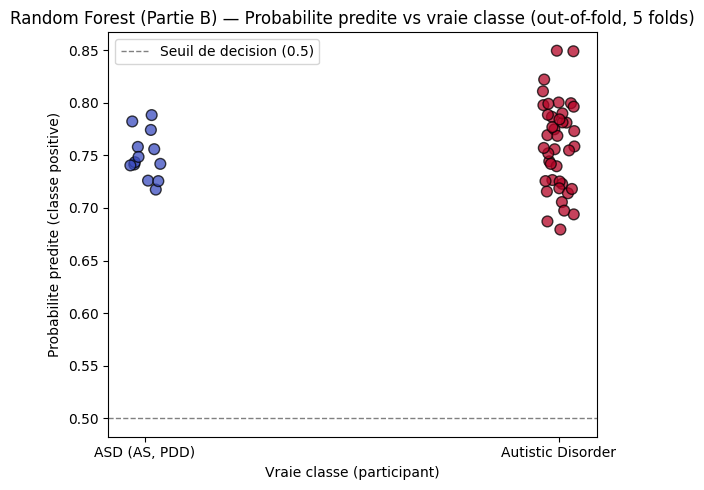

In [ ]:
y_true_arr = np.array(y_true_rf_sal)

plt.figure(figsize=(6, 5))
if y_prob_rf_sal_p.shape[1] == 2:
    proba_plot = y_prob_rf_sal_p[:, 1]
    jitter = (np.random.rand(len(y_true_arr)) - 0.5) * 0.08  
    plt.scatter(y_true_arr + jitter, proba_plot, c=y_true_arr, cmap='coolwarm',
                edgecolor='k', alpha=0.75, s=60)
    plt.axhline(0.5, color='gray', linestyle='--', lw=1, label='Seuil de decision (0.5)')
    plt.xticks(sorted(set(y_true_arr)), le.classes_)
    plt.xlabel("Vraie classe (participant)")
    plt.ylabel("Probabilite predite (classe positive)")
    plt.legend()
else:
    
    proba_plot = y_prob_rf_sal_p[np.arange(len(y_true_arr)), y_true_arr]
    jitter = (np.random.rand(len(y_true_arr)) - 0.5) * 0.08
    plt.scatter(y_true_arr + jitter, proba_plot, c=y_true_arr, cmap='tab10',
                edgecolor='k', alpha=0.75, s=60)
    plt.xticks(sorted(set(y_true_arr)), le.classes_)
    plt.xlabel("Vraie classe (participant)")
    plt.ylabel("Probabilite predite (pour la vraie classe)")

plt.title("Random Forest (Partie B) — Probabilite predite vs vraie classe (out-of-fold, 5 folds)")
plt.tight_layout()
plt.show()


Random Forest (features artisanales, Partie B) — CV 5 folds, seed=42

=== Niveau PARTICIPANT (precision / recall / F1 / accuracy en %) ===
  precision : 38.00 ± 2.26
  recall    : 50.00 ± 0.00
  f1        : 43.15 ± 1.45
  accuracy  : 76.00 ± 4.53
  auc       : 0.5750 ± 0.1542

=== Niveau IMAGE (par chunk) — Random Forest ===
  MAE  : 0.3604 ± 0.0182
  MSE  : 0.1922 ± 0.0147
  RMSE : 0.4381 ± 0.0170
  R2   : -0.0780 ± 0.0285

=== Niveau PARTICIPANT (regression proba vs label) — Random Forest ===
  MAE  : 0.3630 ± 0.0216
  MSE  : 0.1803 ± 0.0202
  RMSE : 0.4241 ± 0.0241
  R2   : -0.0004 ± 0.0269


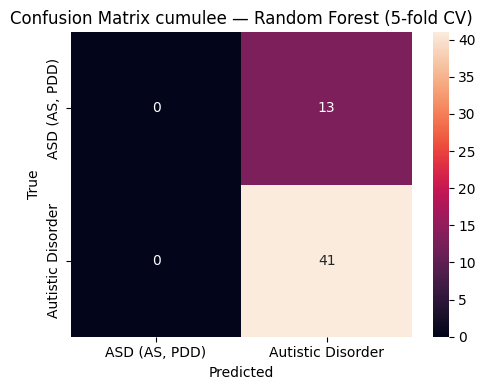


Resultats sauvegardes -> /kaggle/working/rf_saliency_cv5_summary.csv


In [ ]:
metric_cols = [c for c in cv_df.columns if c != 'n_participants_test']
summary = pd.DataFrame({
    'mean': cv_df[metric_cols].mean(),
    'std':  cv_df[metric_cols].std(ddof=1),
})
summary['mean ± std'] = [
    (f"{m:.2f} ± {s:.2f}" if c in ('precision', 'recall', 'f1', 'accuracy') else f"{m:.4f} ± {s:.4f}")
    for c, m, s in zip(summary.index, summary['mean'], summary['std'])
]

print(f"Random Forest (features artisanales, Partie B) — CV {N_FOLDS} folds, seed={SEED}")
print("\n=== Niveau PARTICIPANT (precision / recall / F1 / accuracy en %) ===")
for k in ['precision', 'recall', 'f1', 'accuracy', 'auc']:
    print(f"  {k:<10}: {summary.loc[k, 'mean ± std']}")

print("\n=== Niveau IMAGE (par chunk) — Random Forest ===")
for k in ['MAE_image', 'MSE_image', 'RMSE_image', 'R2_image']:
    print(f"  {k.split('_')[0]:<5}: {summary.loc[k, 'mean ± std']}")

print("\n=== Niveau PARTICIPANT (regression proba vs label) — Random Forest ===")
for k in ['MAE_participant', 'MSE_participant', 'RMSE_participant', 'R2_participant']:
    print(f"  {k.split('_')[0]:<5}: {summary.loc[k, 'mean ± std']}")

prec_rf_sal, rec_rf_sal = summary.loc['precision', 'mean'], summary.loc['recall', 'mean']
f1_rf_sal, acc_rf_sal   = summary.loc['f1', 'mean'], summary.loc['accuracy', 'mean']
auc_rf_sal              = summary.loc['auc', 'mean']

plt.figure(figsize=(5, 4))
sns.heatmap(cm_total, annot=True, fmt="d", xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title(f"Confusion Matrix cumulee — Random Forest ({N_FOLDS}-fold CV)")
plt.tight_layout(); plt.show()

summary.to_csv(os.path.join(CKPT_DIR, 'rf_saliency_cv5_summary.csv'))
cv_df.to_csv(os.path.join(CKPT_DIR, 'rf_saliency_cv5_per_fold.csv'))
print(f"\nResultats sauvegardes -> {CKPT_DIR}/rf_saliency_cv5_summary.csv")

### 10. Courbe ROC (classification) & courbe Loss (regression)


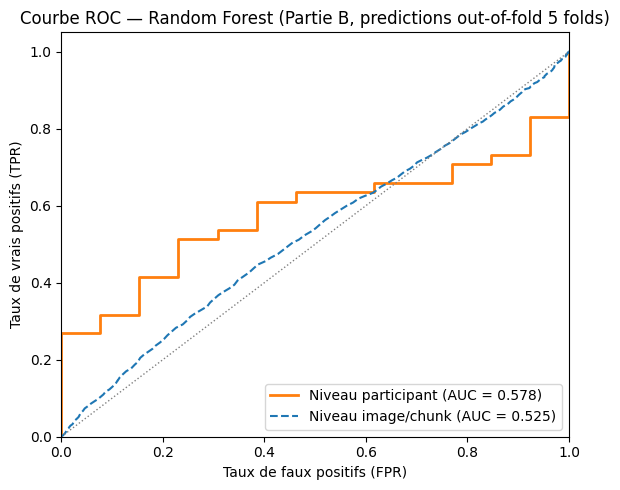

In [ ]:
from sklearn.metrics import roc_curve, auc

# Courbe ROC — Random Forest 
if len(le.classes_) == 2:
    # ---- Niveau image / chunk ----
    fpr_img, tpr_img, _ = roc_curve(y_true_img, y_prob_img)
    roc_auc_img = auc(fpr_img, tpr_img)

    # ---- Niveau participant ----
    fpr_part, tpr_part, _ = roc_curve(y_true_rf_sal, y_prob_rf_sal_p[:, 1])
    roc_auc_part = auc(fpr_part, tpr_part)

    plt.figure(figsize=(6, 5))
    plt.plot(fpr_part, tpr_part, color='tab:orange', lw=2,
             label=f"Niveau participant (AUC = {roc_auc_part:.3f})")
    plt.plot(fpr_img, tpr_img, color='tab:blue', lw=1.5, linestyle='--',
             label=f"Niveau image/chunk (AUC = {roc_auc_img:.3f})")
    plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle=':')
    plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
    plt.xlabel("Taux de faux positifs (FPR)")
    plt.ylabel("Taux de vrais positifs (TPR)")
    plt.title("Courbe ROC — Random Forest (Partie B, predictions out-of-fold 5 folds)")
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()
else:
    print("Courbe ROC non tracee : plus de 2 classes (le.classes_ =", list(le.classes_), ")")


Aucun checkpoint -> calcul de la courbe loss (ajout progressif d'arbres via warm_start).


Courbe loss (n_estimators):   0%|          | 0/30 [00:00<?, ?it/s]

Courbe loss sauvegardee -> /kaggle/working/ckpt_rf_loss_curve.pkl


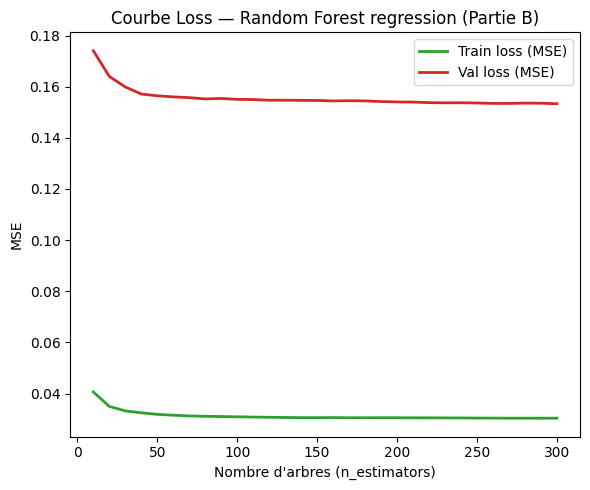

In [ ]:
# Courbe Loss (regression, MSE) en fonction du nombre d'arbres
LOSS_CURVE_CKPT = os.path.join(CKPT_DIR, 'ckpt_rf_loss_curve.pkl')

STEP = max(1, SAL_RF_N_ESTIMATORS // 30)   # ~30 points sur la courbe
N_STEPS = SAL_RF_N_ESTIMATORS // STEP

if os.path.exists(LOSS_CURVE_CKPT):
    print(f"Checkpoint trouve : {LOSS_CURVE_CKPT} -> chargement (pas de recalcul).")
    with open(LOSS_CURVE_CKPT, 'rb') as f:
        n_trees_list, mse_train_list, mse_test_list = pickle.load(f)
else:
    print("Aucun checkpoint -> calcul de la courbe loss (ajout progressif d'arbres via warm_start).")
    rf_curve = RandomForestClassifier(
        n_estimators=STEP, warm_start=True, class_weight='balanced',
        random_state=42, n_jobs=-1
    )
    n_trees_list, mse_train_list, mse_test_list = [], [], []
    for step in tqdm(range(1, N_STEPS + 1), desc="Courbe loss (n_estimators)"):
        rf_curve.n_estimators = step * STEP
        rf_curve.fit(X_sal_feat_train, y_sal_train)

        p_train = rf_curve.predict_proba(X_sal_feat_train)[:, 1]
        p_test  = rf_curve.predict_proba(X_sal_feat_test)[:, 1]

        n_trees_list.append(step * STEP)
        mse_train_list.append(mean_squared_error(y_sal_train, p_train))
        mse_test_list.append(mean_squared_error(y_sal_test, p_test))

    with open(LOSS_CURVE_CKPT, 'wb') as f:
        pickle.dump((n_trees_list, mse_train_list, mse_test_list), f)
    print(f"Courbe loss sauvegardee -> {LOSS_CURVE_CKPT}")

plt.figure(figsize=(6, 5))
plt.plot(n_trees_list, mse_train_list, color='tab:green', lw=2, label="Train loss (MSE)")
plt.plot(n_trees_list, mse_test_list, color='tab:red', lw=2, label="Val loss (MSE)")
plt.xlabel("Nombre d'arbres (n_estimators)")
plt.ylabel("MSE")
plt.title("Courbe Loss — Random Forest regression (Partie B)")
plt.legend()
plt.tight_layout()
plt.show()


Aucun checkpoint -> calcul des 3 courbes (ajout progressif d'arbres via warm_start).


Courbe loss (n_estimators):   0%|          | 0/30 [00:00<?, ?it/s]

Courbe loss (3 panneaux) sauvegardee -> /kaggle/working/ckpt_rf_loss_curve_3panels.pkl


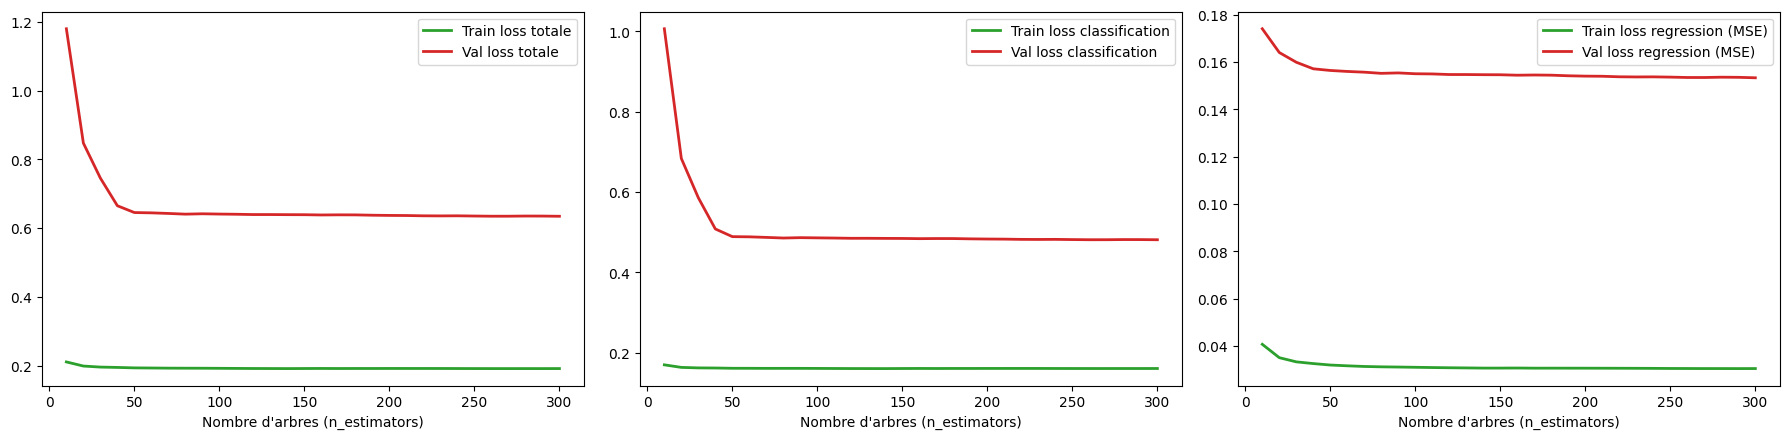

In [ ]:
from sklearn.metrics import log_loss, mean_squared_error

LOSS_CURVE_3P_CKPT = os.path.join(CKPT_DIR, 'ckpt_rf_loss_curve_3panels.pkl')

STEP = max(1, SAL_RF_N_ESTIMATORS // 30)   # ~30 points sur la courbe
N_STEPS = SAL_RF_N_ESTIMATORS // STEP

if os.path.exists(LOSS_CURVE_3P_CKPT):
    print(f"Checkpoint trouve : {LOSS_CURVE_3P_CKPT} -> chargement (pas de recalcul).")
    with open(LOSS_CURVE_3P_CKPT, 'rb') as f:
        (n_trees_list,
         train_logloss_list, val_logloss_list,
         train_mse_list, val_mse_list,
         train_total_list, val_total_list) = pickle.load(f)
else:
    print("Aucun checkpoint -> calcul des 3 courbes (ajout progressif d'arbres via warm_start).")
    rf_curve = RandomForestClassifier(
        n_estimators=STEP, warm_start=True, class_weight='balanced',
        random_state=42, n_jobs=-1
    )

    n_trees_list        = []
    train_logloss_list  = []   # "classification loss" train (cross-entropy)
    val_logloss_list    = []   # "classification loss" val
    train_mse_list      = []   # "regression loss" train (MSE sur les probas)
    val_mse_list        = []   # "regression loss" val
    train_total_list    = []   # "loss totale" train = logloss + mse
    val_total_list       = []   # "loss totale" val   = logloss + mse

    for step in tqdm(range(1, N_STEPS + 1), desc="Courbe loss (n_estimators)"):
        rf_curve.n_estimators = step * STEP
        rf_curve.fit(X_sal_feat_train, y_sal_train)

        p_train = rf_curve.predict_proba(X_sal_feat_train)
        p_test  = rf_curve.predict_proba(X_sal_feat_test)

        ll_train  = log_loss(y_sal_train, p_train, labels=rf_curve.classes_)
        ll_val    = log_loss(y_sal_test, p_test, labels=rf_curve.classes_)
        mse_train = mean_squared_error(y_sal_train, p_train[:, 1])
        mse_val   = mean_squared_error(y_sal_test, p_test[:, 1])

        n_trees_list.append(step * STEP)
        train_logloss_list.append(ll_train)
        val_logloss_list.append(ll_val)
        train_mse_list.append(mse_train)
        val_mse_list.append(mse_val)
        train_total_list.append(ll_train + mse_train)
        val_total_list.append(ll_val + mse_val)

    with open(LOSS_CURVE_3P_CKPT, 'wb') as f:
        pickle.dump((n_trees_list,
                     train_logloss_list, val_logloss_list,
                     train_mse_list, val_mse_list,
                     train_total_list, val_total_list), f)
    print(f"Courbe loss (3 panneaux) sauvegardee -> {LOSS_CURVE_3P_CKPT}")

# Figure a 3 sous-graphiques, meme structure que la figure CNN-LSTM
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].plot(n_trees_list, train_total_list, color='tab:green', lw=2, label="Train loss totale")
axes[0].plot(n_trees_list, val_total_list, color='tab:red', lw=2, label="Val loss totale")
axes[0].set_xlabel("Nombre d'arbres (n_estimators)")
axes[0].legend()

axes[1].plot(n_trees_list, train_logloss_list, color='tab:green', lw=2, label="Train loss classification")
axes[1].plot(n_trees_list, val_logloss_list, color='tab:red', lw=2, label="Val loss classification")
axes[1].set_xlabel("Nombre d'arbres (n_estimators)")
axes[1].legend()

axes[2].plot(n_trees_list, train_mse_list, color='tab:green', lw=2, label="Train loss regression (MSE)")
axes[2].plot(n_trees_list, val_mse_list, color='tab:red', lw=2, label="Val loss regression (MSE)")
axes[2].set_xlabel("Nombre d'arbres (n_estimators)")
axes[2].legend()

plt.tight_layout()
plt.show()

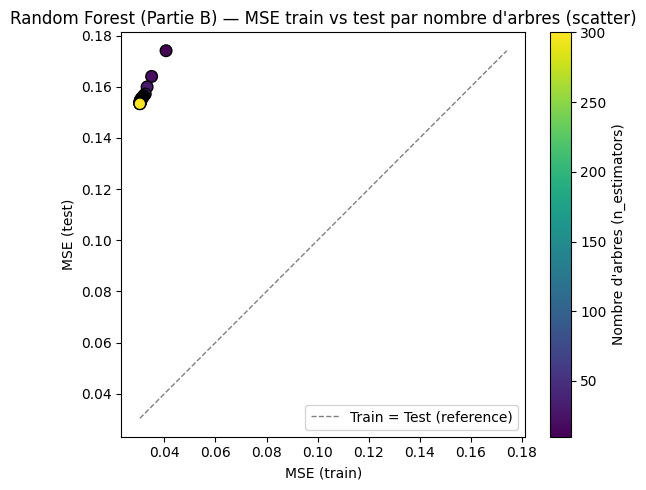

In [ ]:
n_trees_arr = np.array(n_trees_list)

plt.figure(figsize=(6, 5))
sc = plt.scatter(mse_train_list, mse_test_list, c=n_trees_arr, cmap='viridis',
                  edgecolor='k', s=70)
lims = [min(min(mse_train_list), min(mse_test_list)),
        max(max(mse_train_list), max(mse_test_list))]
plt.plot(lims, lims, color='gray', linestyle='--', lw=1, label='Train = Test (reference)')

cbar = plt.colorbar(sc)
cbar.set_label("Nombre d'arbres (n_estimators)")

plt.xlabel("MSE (train)")
plt.ylabel("MSE (test)")
plt.title("Random Forest (Partie B) — MSE train vs test par nombre d'arbres (scatter)")
plt.legend()
plt.tight_layout()
plt.show()
